# Week 44: trying to get the Hessian out of tree derivative estimates

I'm trying to take the first derivative estimate from Nathan's *Regression Trees Know Calculus* paper and see if I can use it to estimate the Hessian. Started with 2D, then went to D dimensions, and then put it into an actual sklearn regression tree.

The part I kept getting hung up on: gamma_i is an estimated first derivative, but where exactly is that derivative evaluated? For quadratics with uniform box means I can derive an effective location z_i. Then I can compare two nodes A and B that split the same coordinate. The difference gamma_B - gamma_A and the displacement v_AB = z_B - z_A give an equation involving one row of the Hessian.

What I'm checking here:
- 2D on made-up rectangular regions, exact box means. No fitted tree yet.
- D dimensions, same exact calculation. D=4 in the run below.
- A real CART fitted to sampled quadratic data. Check the empirical child means against exact means on the exact same tree partitions. Important because these are NOT the same thing.

This is a quadratic check, not some proof that I can get the Hessian for any smooth function. Also not the full physics-informed tree. Pair selection and error from the child means are still problems.


## Shared mathematical construction

For every internal node $i$, the RTC first-derivative estimate, written using the half-width convention, is

$$
\gamma_i=\frac{\widehat\mu_r^i-\widehat\mu_l^i}{(u_{\sigma_i}^i-l_{\sigma_i}^i)/2}.
$$

For a quadratic under exact uniform averaging, the corresponding *effective first-derivative location* is

$$
z_{i,j}=\begin{cases}
(l_j^i+\tau^i+u_j^i)/3,&j=\sigma_i,\\
(l_j^i+u_j^i)/2,&j\ne\sigma_i.
\end{cases}
$$

**Why $1/3$ and $1/2$?** The child-average contrast of $x_j^2$ produces $(l_j^i+\tau^i+u_j^i)/3$ after dividing by the child-centroid separation; coordinates that are not split are uniformly averaged over their whole interval, giving $(l_j^i+u_j^i)/2$. Thus $\gamma_i=\partial_{\sigma_i}f(z_i)$ for every quadratic with exact uniform regional means.

Choose nodes $A,B$ **with the same split coordinate** $\sigma_A=\sigma_B=j$. Then compute

$$
v_{AB}=z_B-z_A,\qquad \gamma_B-\gamma_A=\sum_{k=1}^D Q_{jk}v_{AB,k}.
$$

Here $v_{AB}$ is a **displacement**, not necessarily a unit direction. Each pair adds one linear equation. Collecting the $D(D+1)/2$ distinct Hessian entries in a vector $q$ gives $Mq=y$. We solve only if $M$ has full column rank. The equation is exact only in the ideal quadratic case described above.

In [1]:
import numpy as np
import matplotlib.pyplot as plt
from collections import Counter
from sklearn.tree import DecisionTreeRegressor

np.set_printoptions(precision=5, suppress=True)
RANDOM_SEED = 20261029

## Utilities: exact box means, RTC derivative contrasts, effective locations, and linear-system assembly

In [2]:
def quadratic_box_mean(lower, upper, Q, beta, c):
    """Exact E[f(X)] for independent uniform coordinates X_j ~ U(lower_j,upper_j).

    f(x) = (1/2)x.T @ Q @ x + beta.T @ x + c.
    Uses E[X_j^2] = E[X_j]^2 + Var(X_j), Var(X_j)=(upper_j-lower_j)^2/12.
    """
    lower, upper = np.asarray(lower, float), np.asarray(upper, float)
    mid = (lower + upper) / 2
    variance = (upper - lower)**2 / 12
    return float(0.5 * mid @ Q @ mid + 0.5 * np.dot(np.diag(Q), variance)
                 + beta @ mid + c)


def make_node(node_id, lower, upper, sigma, tau, Q, beta, c, empirical_means=None):
    """Create a node record; use either exact box means or a supplied pair of sample means.

    Python uses 0-based coordinate indices, while mathematical sigma_i ranges from 1 to D.
    """
    lower = np.array(lower, dtype=float, copy=True)
    upper = np.array(upper, dtype=float, copy=True)
    if not (lower[sigma] < tau < upper[sigma]):
        raise ValueError('A split threshold must be strictly inside its node interval.')
    left_upper, right_lower = upper.copy(), lower.copy()
    left_upper[sigma] = tau
    right_lower[sigma] = tau
    if empirical_means is None:
        mu_l = quadratic_box_mean(lower, left_upper, Q, beta, c)
        mu_r = quadratic_box_mean(right_lower, upper, Q, beta, c)
        source = 'oracle'
    else:
        mu_l, mu_r = map(float, empirical_means)
        source = 'empirical'
    gamma = (mu_r - mu_l) / ((upper[sigma] - lower[sigma]) / 2)
    z = (lower + upper) / 2
    z[sigma] = (lower[sigma] + tau + upper[sigma]) / 3
    return dict(id=int(node_id), lower=lower, upper=upper, sigma=int(sigma), tau=float(tau),
                mu_l=mu_l, mu_r=mu_r, gamma=float(gamma), z=z, source=source)


def synthetic_regions(D, count_per_sigma, Q, beta, c, seed):
    """Independent box regions for algebra verification (NOT nodes from one fitted tree)."""
    rng = np.random.default_rng(seed)
    nodes = []
    for sigma in range(D):
        for _ in range(count_per_sigma):
            lower = rng.uniform(0.0, 0.42, size=D)
            upper = rng.uniform(0.58, 1.0, size=D)
            tau = lower[sigma] + rng.uniform(0.2, 0.8) * (upper[sigma]-lower[sigma])
            nodes.append(make_node(len(nodes), lower, upper, sigma, tau, Q, beta, c))
    return nodes


def upper_triangle_index(D):
    return [(i, j) for i in range(D) for j in range(i, D)]


def pair_system(nodes, D, k_neighbors=7, target=None, radius=None, min_separation=1e-8):
    """Same-split-coordinate nearest-neighbor pairing; no structural parent/child requirement.

    Geometry-only selection; does not use observed derivative differences when pairing.
    """
    indices = upper_triangle_index(D)
    column = {entry: idx for idx, entry in enumerate(indices)}
    M, y, pairs = [], [], []
    if target is not None and radius is not None:
        nodes = [r for r in nodes if np.linalg.norm(r['z'] - target) <= radius]
    for sigma in range(D):
        group = [r for r in nodes if r['sigma'] == sigma]
        seen = set()
        for ia, A in enumerate(group):
            distances = np.array([np.linalg.norm(B['z'] - A['z']) for B in group])
            choices = [ib for ib in np.argsort(distances) if ib != ia][:k_neighbors]
            for ib in choices:
                B = group[ib]
                if distances[ib] < min_separation:
                    continue
                key = tuple(sorted((A['id'], B['id'])))
                if key in seen:
                    continue
                seen.add(key)
                v_AB = B['z'] - A['z']
                row = np.zeros(len(indices))
                for coord in range(D):
                    row[column[tuple(sorted((sigma, coord)))]] = v_AB[coord]
                M.append(row)
                y.append(B['gamma'] - A['gamma'])
                pairs.append(dict(A=A['id'], B=B['id'], sigma=sigma, v_AB=v_AB))
    return np.asarray(M).reshape(-1, len(indices)), np.asarray(y), pairs


def recover_hessian(M, y, D):
    """Least-squares recovery with a full-column-rank guard and diagnostics."""
    m = D*(D+1)//2
    rank = int(np.linalg.matrix_rank(M)) if len(M) else 0
    result = dict(rank=rank, required_rank=m, equations=M.shape[0], identifiable=(rank == m))
    if rank < m:
        result['Q_hat'] = None
        return result
    q_hat, *_ = np.linalg.lstsq(M, y, rcond=None)
    Q_hat = np.zeros((D,D))
    for (j,k), val in zip(upper_triangle_index(D), q_hat):
        Q_hat[j,k] = Q_hat[k,j] = val
    singular_values = np.linalg.svd(M, compute_uv=False)
    result.update(Q_hat=Q_hat, q_hat=q_hat,
                  condition_number=float(singular_values[0]/singular_values[-1]),
                  equation_RMSE=float(np.linalg.norm(M @ q_hat - y)/np.sqrt(len(y))))
    return result


def show_result(label, M, y, result, Q_true):
    print(f'\n{label}')
    print(f'Equations: {result["equations"]} | Rank: {result["rank"]}/{result["required_rank"]} | '
          f'Identifiable: {result["identifiable"]}')
    if result['Q_hat'] is None:
        print('Hessian not identifiable from these pairs.')
        return
    print(f'Matrix condition number: {result["condition_number"]:.3g}')
    print(f'Equation RMSE:          {result["equation_RMSE"]:.6g}')
    print(f'Frobenius error:        {np.linalg.norm(result["Q_hat"]-Q_true):.6g}')
    print('Q true =\n', Q_true)
    print('Q recovered =\n', result['Q_hat'])

## Stage 1. A complete 2D sample run (without fitting a tree)

Build a collection of independent rectangular regions in $[0,1]^2$, assign split coordinates and thresholds, and calculate child means **by integrating the known quadratic over each box**. These regions check the algebra without CART sampling or tree structure. They are not asserted to be nodes of one fitted regression tree.

In [3]:
Q_2 = np.array([[4.0, 1.5],
                [1.5, 3.0]])
beta_2 = np.array([-1.0, 2.0])
c_2 = 0.7
nodes_2 = synthetic_regions(D=2, count_per_sigma=12, Q=Q_2, beta=beta_2, c=c_2,
                            seed=RANDOM_SEED)
M_2, y_2, pairs_2 = pair_system(nodes_2, D=2, k_neighbors=5)
result_2 = recover_hessian(M_2, y_2, D=2)
show_result('STAGE 1: 2D, exact uniform box means', M_2, y_2, result_2, Q_2)
assert result_2['identifiable']
assert np.allclose(result_2['Q_hat'], Q_2, atol=1e-10)


STAGE 1: 2D, exact uniform box means
Equations: 72 | Rank: 3/3 | Identifiable: True
Matrix condition number: 1.43
Equation RMSE:          1.7966e-15
Frobenius error:        5.0634e-15
Q true =
 [[4.  1.5]
 [1.5 3. ]]
Q recovered =
 [[4.  1.5]
 [1.5 3. ]]


### Inspect one actual pair: why the coefficients come from the displacement

In [4]:
example_pair = next(p for p in pairs_2 if abs(p['v_AB'][0])>1e-3 and abs(p['v_AB'][1])>1e-3)
A = nodes_2[example_pair['A']]
B = nodes_2[example_pair['B']]
v_AB = example_pair['v_AB']
print('Node A =', A['id'], '| split coordinate sigma_A (math indexing) =', A['sigma']+1)
print('Node B =', B['id'], '| split coordinate sigma_B (math indexing) =', B['sigma']+1)
print('z_A =', A['z'], '| gamma_A =', round(A['gamma'], 7))
print('z_B =', B['z'], '| gamma_B =', round(B['gamma'], 7))
print('v_AB = z_B - z_A =', v_AB)
print('Observed gamma_B - gamma_A =', B['gamma']-A['gamma'])
print('Predicted Q[sigma_A,:] @ v_AB =', Q_2[A['sigma']] @ v_AB)
print('Corresponding system row:', M_2[pairs_2.index(example_pair)])

Node A = 0 | split coordinate sigma_A (math indexing) = 1
Node B = 4 | split coordinate sigma_B (math indexing) = 1
z_A = [0.63404 0.67272] | gamma_A = 2.5452476
z_B = [0.58188 0.51108] | gamma_B = 2.0941435
v_AB = z_B - z_A = [-0.05216 -0.16165]
Observed gamma_B - gamma_A = -0.4511040871619989
Predicted Q[sigma_A,:] @ v_AB = -0.4511040871620006
Corresponding system row: [-0.05216 -0.16165  0.     ]


**Interpretation.** The scalar $\gamma_B-\gamma_A$ is the change in one component of the gradient. The displacement $v_{AB}$ records the changes in the **input coordinates**. Their relationship is linear for a quadratic: $\gamma_B-\gamma_A=\sum_j Q_{\sigma_A,j}v_{AB,j}$. We do not divide by one coordinate unless the other contributions have been accounted for.

## Stage 2. The identical calculation in $D$ dimensions

Change `D_nd` below to 3 or 5 and rerun this stage. The Hessian has $D(D+1)/2$ unknown entries. No new pair types are required, and the pair construction still uses only $A,B$, $\sigma_i$, $\gamma_i$, $z_i$, and $v_{AB}$.

In [5]:
D_nd = 4
rng_nd = np.random.default_rng(RANDOM_SEED + 1)
Q_nd = rng_nd.normal(0, 0.45, size=(D_nd,D_nd))
Q_nd = (Q_nd + Q_nd.T)/2
np.fill_diagonal(Q_nd, np.linspace(2.8,4.5,D_nd))
beta_nd = np.linspace(-1.0,1.5,D_nd)
c_nd = 0.2
nodes_nd = synthetic_regions(D_nd, count_per_sigma=20, Q=Q_nd,
                             beta=beta_nd, c=c_nd, seed=RANDOM_SEED + 2)
M_nd, y_nd, pairs_nd = pair_system(nodes_nd, D_nd, k_neighbors=6)
result_nd = recover_hessian(M_nd, y_nd, D_nd)
show_result(f'STAGE 2: D={D_nd}, exact uniform box means', M_nd, y_nd, result_nd, Q_nd)
assert result_nd['identifiable']
assert np.allclose(result_nd['Q_hat'], Q_nd, atol=1e-10)
print(f'Unknown Hessian entries: {D_nd*(D_nd+1)//2}; pairs used: {len(pairs_nd)}')


STAGE 2: D=4, exact uniform box means
Equations: 325 | Rank: 10/10 | Identifiable: True
Matrix condition number: 1.68
Equation RMSE:          1.74488e-15
Frobenius error:        1.57951e-14
Q true =
 [[ 2.8      0.68082 -0.14135  0.01368]
 [ 0.68082  3.36667  0.29064  0.01836]
 [-0.14135  0.29064  3.93333 -0.08043]
 [ 0.01368  0.01836 -0.08043  4.5    ]]
Q recovered =
 [[ 2.8      0.68082 -0.14135  0.01368]
 [ 0.68082  3.36667  0.29064  0.01836]
 [-0.14135  0.29064  3.93333 -0.08043]
 [ 0.01368  0.01836 -0.08043  4.5    ]]
Unknown Hessian entries: 10; pairs used: 325


## Stage 3. Bring the algorithm into a fitted regression tree

Fit `DecisionTreeRegressor` on **uniformly sampled**, noiseless quadratic responses. Walk the fitted tree to recover each internal node's rectangular bounds, split coordinate, split threshold, and the means stored in its two children.

For each internal node, construct **two versions** of the same $\gamma_i$:

- **Empirical CART:** the split-child means stored in `tree_.value`.
- **Oracle on exactly the same CART geometry:** replace those sample means by exact uniform quadratic box averages, without changing **any** fitted split.

If the oracle succeeds but the empirical version is less accurate, the difference is due to how the node averages approximate spatial averages, not the rank of the selected Hessian equations.

**Important:** sklearn's CART split decisions depend on observed responses. The RTC paper's simplifying asymptotic assumptions for gradient consistency do not directly establish Hessian consistency for these fitted trees.

In [6]:
def extract_cart_nodes(model, Q, beta, c, lower=None, upper=None):
    """Read internal-node geometry and child means from a fitted sklearn tree.

    Returns two record collections on IDENTICAL fitted geometry, plus leaf rectangles.
    """
    tree = model.tree_
    D = model.n_features_in_
    if lower is None: lower = np.zeros(D)
    if upper is None: upper = np.ones(D)
    empirical, oracle, leaves = [], [], []

    def visit(node_id, lo, hi):
        left, right = int(tree.children_left[node_id]), int(tree.children_right[node_id])
        if left == -1:
            leaves.append((lo.copy(), hi.copy(), float(tree.value[node_id,0,0])))
            return
        sigma = int(tree.feature[node_id])
        tau = float(tree.threshold[node_id])
        if not (lo[sigma] < tau < hi[sigma]):
            raise AssertionError('Invalid bounds reconstructed from tree')
        means = (float(tree.value[left,0,0]), float(tree.value[right,0,0]))
        empirical.append(make_node(node_id, lo, hi, sigma, tau, Q,beta,c, means))
        oracle.append(make_node(node_id, lo, hi, sigma, tau, Q,beta,c))
        left_hi = hi.copy(); left_hi[sigma] = tau
        right_lo = lo.copy(); right_lo[sigma] = tau
        visit(left, lo.copy(), left_hi)
        visit(right, right_lo, hi.copy())

    visit(0, np.asarray(lower,float), np.asarray(upper,float))
    return empirical, oracle, leaves


def compare_on_same_tree(D, Q, beta, c, n_samples, max_leaf_nodes, min_samples_leaf,
                         seed, k_neighbors=8):
    rng = np.random.default_rng(seed)
    X = rng.uniform(0.0, 1.0, size=(n_samples,D))
    y = 0.5 * np.einsum('ni,ij,nj->n',X,Q,X) + X @ beta + c
    model = DecisionTreeRegressor(max_leaf_nodes=max_leaf_nodes,
                                  min_samples_leaf=min_samples_leaf,
                                  random_state=seed)
    model.fit(X,y)
    empirical, oracle, leaves = extract_cart_nodes(model,Q,beta,c)
    M_e,y_e,pairs_e = pair_system(empirical,D,k_neighbors=k_neighbors)
    M_o,y_o,pairs_o = pair_system(oracle,D,k_neighbors=k_neighbors)
    assert [(p['A'],p['B'],p['sigma']) for p in pairs_e] == [
            (p['A'],p['B'],p['sigma']) for p in pairs_o]
    assert np.array_equal(M_e,M_o), 'Geometry must not change between modes'
    result_e = recover_hessian(M_e,y_e,D)
    result_o = recover_hessian(M_o,y_o,D)
    print('Tree node counts:', len(empirical), 'internal,', len(leaves), 'leaves')
    print('Internal split counts by coordinate (1-based):',
          {j+1:sum(n['sigma']==j for n in empirical) for j in range(D)})
    show_result('Oracle means on CART partitions',M_o,y_o,result_o,Q)
    show_result('Empirical means from fitted CART',M_e,y_e,result_e,Q)
    print('Empirical vs oracle gamma RMSE:',
          np.sqrt(np.mean([(a['gamma']-b['gamma'])**2
                           for a,b in zip(empirical,oracle)])))
    assert result_o['identifiable'] and np.allclose(result_o['Q_hat'],Q,atol=1e-9)
    return model, empirical, oracle, leaves, result_o, result_e

### Stage 3a. Fitted **2D** CART: compare exact means and empirical means on the same tree

In [7]:
cart_2, empirical_2, oracle_2, leaf_boxes_2, oracle_fit_2, empirical_fit_2 = compare_on_same_tree(
    D=2, Q=Q_2, beta=beta_2, c=c_2,
    n_samples=60000, max_leaf_nodes=100, min_samples_leaf=250,
    seed=RANDOM_SEED+3, k_neighbors=9)

Tree node counts: 99 internal, 100 leaves
Internal split counts by coordinate (1-based): {1: 50, 2: 49}

Oracle means on CART partitions
Equations: 531 | Rank: 3/3 | Identifiable: True
Matrix condition number: 1.65
Equation RMSE:          6.61694e-15
Frobenius error:        3.36747e-15
Q true =
 [[4.  1.5]
 [1.5 3. ]]
Q recovered =
 [[4.  1.5]
 [1.5 3. ]]

Empirical means from fitted CART
Equations: 531 | Rank: 3/3 | Identifiable: True
Matrix condition number: 1.65
Equation RMSE:          0.173236
Frobenius error:        0.222308
Q true =
 [[4.  1.5]
 [1.5 3. ]]
Q recovered =
 [[4.05067 1.55457]
 [1.55457 2.79777]]
Empirical vs oracle gamma RMSE: 0.12200823473167925


### Inspect one selected pair from the fitted CART

The fitted model contains many internal nodes. These are **real CART node IDs**, rather than invented labels. The selection algorithm names any chosen pair $A,B$ and reports the two split coordinates, derivative estimates, effective locations, and displacement. The *same pair* is then evaluated with empirical means and oracle means.

In [8]:
M_cart, y_cart, selected_cart_pairs = pair_system(empirical_2, D=2, k_neighbors=9)
A_id, B_id = selected_cart_pairs[0]['A'], selected_cart_pairs[0]['B']
emp_by_id = {node['id']:node for node in empirical_2}
oracle_by_id = {node['id']:node for node in oracle_2}
for label, by_id in [('Empirical CART',emp_by_id),('Same nodes, oracle box means',oracle_by_id)]:
    A, B = by_id[A_id], by_id[B_id]
    print('\n',label)
    print(f'Nodes A={A_id}, B={B_id}; shared split coordinate sigma={A["sigma"]+1}')
    print('Node A bounds:',A['lower'], A['upper'],'| threshold:',A['tau'])
    print('Node B bounds:',B['lower'], B['upper'],'| threshold:',B['tau'])
    print('z_A=',A['z'],'z_B=',B['z'])
    print('v_AB=',B['z']-A['z'])
    print('gamma_B - gamma_A=',B['gamma']-A['gamma'])
    print('Quadratic prediction =',Q_2[A['sigma']] @ (B['z']-A['z']))


 Empirical CART
Nodes A=5, B=25; shared split coordinate sigma=1
Node A bounds: [0. 0.] [1.     0.2862] | threshold: 0.6945894062519073
Node B bounds: [0. 0.] [0.69459 0.14796] | threshold: 0.510868102312088
z_A= [0.56486 0.1431 ] z_B= [0.40182 0.07398]
v_AB= [-0.16304 -0.06912]
gamma_B - gamma_A= -0.7348694191478623
Quadratic prediction = -0.7558573068430028

 Same nodes, oracle box means
Nodes A=5, B=25; shared split coordinate sigma=1
Node A bounds: [0. 0.] [1.     0.2862] | threshold: 0.6945894062519073
Node B bounds: [0. 0.] [0.69459 0.14796] | threshold: 0.510868102312088
z_A= [0.56486 0.1431 ] z_B= [0.40182 0.07398]
v_AB= [-0.16304 -0.06912]
gamma_B - gamma_A= -0.7558573068430022
Quadratic prediction = -0.7558573068430028


### Visualize the first three levels of the actual fitted CART tree

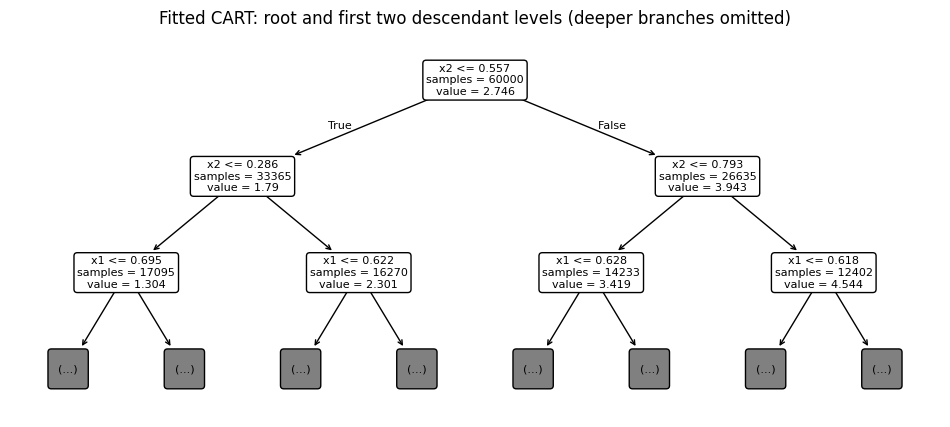

In [9]:
from sklearn.tree import plot_tree
fig, ax = plt.subplots(figsize=(12, 5))
plot_tree(cart_2, max_depth=2, feature_names=['x1','x2'], filled=False,
          impurity=False, rounded=True, fontsize=8, ax=ax)
ax.set_title('Fitted CART: root and first two descendant levels (deeper branches omitted)')
plt.show()

### Visualize the partition actually learned by CART (2D)

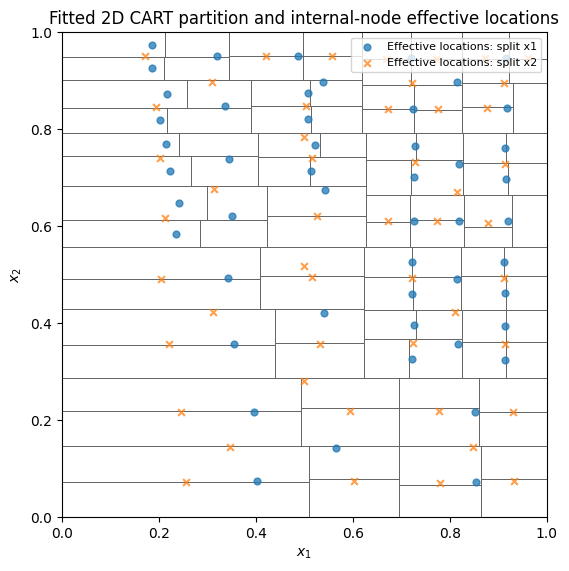

In [10]:
from matplotlib.patches import Rectangle
fig, ax = plt.subplots(figsize=(7.5,6.3))
for lo,hi,val in leaf_boxes_2:
    ax.add_patch(Rectangle(lo, *(hi-lo), fill=False, linewidth=0.65, edgecolor='0.40'))
for j, mark in [(0,'o'),(1,'x')]:
    Z = np.array([n['z'] for n in empirical_2 if n['sigma']==j])
    if len(Z):
        ax.scatter(Z[:,0],Z[:,1],s=24,marker=mark,alpha=0.75,
                   label=f'Effective locations: split x{j+1}')
ax.set(xlim=(0,1),ylim=(0,1),xlabel='$x_1$',ylabel='$x_2$',
       title='Fitted 2D CART partition and internal-node effective locations')
ax.set_aspect('equal')
ax.legend(fontsize=8, loc='upper right')
plt.show()

### Stage 3b. Fitted **$D$-dimensional** CART

Use the same `D_nd` and $Q$ as Stage 2. We cannot plot a $D$-dimensional partition on a 2D page, but we can still inspect split counts, rank, recovery errors, and matrix heatmaps. The implementation is the same as the 2D run.

In [11]:
cart_nd, empirical_nd, oracle_nd, leaf_boxes_nd, oracle_fit_nd, empirical_fit_nd = compare_on_same_tree(
    D=D_nd, Q=Q_nd, beta=beta_nd, c=c_nd,
    n_samples=100000, max_leaf_nodes=180, min_samples_leaf=260,
    seed=RANDOM_SEED+4, k_neighbors=10)

Tree node counts: 179 internal, 180 leaves
Internal split counts by coordinate (1-based): {1: 43, 2: 46, 3: 34, 4: 56}

Oracle means on CART partitions
Equations: 1079 | Rank: 10/10 | Identifiable: True
Matrix condition number: 17.5
Equation RMSE:          3.33361e-15
Frobenius error:        1.8217e-14
Q true =
 [[ 2.8      0.68082 -0.14135  0.01368]
 [ 0.68082  3.36667  0.29064  0.01836]
 [-0.14135  0.29064  3.93333 -0.08043]
 [ 0.01368  0.01836 -0.08043  4.5    ]]
Q recovered =
 [[ 2.8      0.68082 -0.14135  0.01368]
 [ 0.68082  3.36667  0.29064  0.01836]
 [-0.14135  0.29064  3.93333 -0.08043]
 [ 0.01368  0.01836 -0.08043  4.5    ]]

Empirical means from fitted CART
Equations: 1079 | Rank: 10/10 | Identifiable: True
Matrix condition number: 17.5
Equation RMSE:          0.169903
Frobenius error:        0.204578
Q true =
 [[ 2.8      0.68082 -0.14135  0.01368]
 [ 0.68082  3.36667  0.29064  0.01836]
 [-0.14135  0.29064  3.93333 -0.08043]
 [ 0.01368  0.01836 -0.08043  4.5    ]]
Q recover

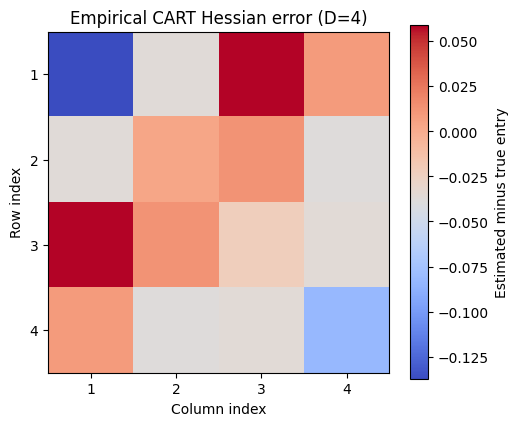

In [12]:
fig, ax = plt.subplots(figsize=(5.5,4.6))
image = ax.imshow(empirical_fit_nd['Q_hat'] - Q_nd, cmap='coolwarm')
ax.set_xticks(range(D_nd),[f'{j+1}' for j in range(D_nd)])
ax.set_yticks(range(D_nd),[f'{j+1}' for j in range(D_nd)])
ax.set(xlabel='Column index',ylabel='Row index',
       title=f'Empirical CART Hessian error (D={D_nd})')
fig.colorbar(image,ax=ax,label='Estimated minus true entry')
plt.show()

## Where I'm at after running it

- The algebra works on quadratic functions if I use exact uniform regional means. Both the 2D and D-dimensional runs recover Q up to floating-point error.
- For fitted CART, the tree structure is real, but the child means are sample averages. Hessian error is not zero anymore. If I swap in exact box averages using those same tree boundaries, I get Q back. So at least I can tell which part is causing the mismatch.
- The pairing rule is pretty basic: same splitting coordinate, then nearby effective locations. Rank of the matrix tells me if I can even identify Q. I still don't know if nearest neighbors are actually a good idea for a general smooth f.
- I was mixing up gradient and Hessian earlier. Gamma is a first-derivative estimate. Comparing gammas at different locations is what gives information about the Hessian. The displacement v_AB isn't a derivative. It's how far the two effective locations are apart in each coordinate.

**Still need to figure out:** what happens beyond quadratics; whether the effective locations give a useful approximation for C^2 functions; how shrinking cells, sample noise and tiny displacements affect the estimate; which node pairs to choose without getting a nearly singular system. Honestly the linear solve is the easy part. The geometry and estimation error are the headache.

Notation in the code is zero-based for numpy; mathematical sigma_i runs from 1 to D. No physics penalty has been added yet.
